# Peeking, Early Stopping, and Sequential Testing

**What you'll learn**

- How badly daily significance checks break a fixed-horizon test: an A/A simulation where
  the nominal 5% false-positive rate inflates to roughly 25–30%, with the p-value paths
  that cause it.
- *Why* it happens: multiple looks are multiple (highly correlated) tests on accumulating
  data — and why Bonferroni is the wrong fix.
- Group-sequential testing done properly: an O'Brien–Fleming-style alpha-spending
  function, boundaries computed with the actual Lan–DeMets recursive-integration
  algorithm, verified by simulation — FPR controlled, early stopping real, the price a
  slightly stricter final look.
- Always-valid inference: a working mixture SPRT (mSPRT) for proportions — the machinery
  behind "peek all you want" commercial stats engines — with anytime validity under H0
  demonstrated over 60 days of daily monitoring.
- An honest answer to "doesn't Bayesian A/B testing solve peeking?": posterior-threshold
  stopping inflates frequentist errors just like p-value peeking (we simulate it), and
  what expected-loss stopping does and does not guarantee.
- The practical playbook: when fixed-horizon is fine, what platforms like Optimizely do,
  and the pre-registration discipline that makes any of this work.

**Why it matters in interviews**

- "The PM checks the dashboard every day and wants to stop early — what do you tell
  them?" is one of the most common senior A/B-testing questions. The strong answer
  quantifies the damage and offers a constructive alternative, not just "don't."
- "Explain alpha spending" and "how would you build always-valid p-values" show up in
  experimentation-platform interviews (Optimizely/Statsig/Eppo-style roles and any
  company with an in-house platform).
- "Does Bayesian A/B testing fix peeking?" is a favorite trap: both naive yes and naive
  no lose points. The nuanced answer is demonstrated here in code.

Everything is simulated so ground truth is known. Related notebooks: the testing
machinery is in
[../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb),
peeking's cousin p-hacking in
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb),
horizon planning in [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb)
(shorter tests via variance reduction:
[03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb)), and the
Bayesian decision framework in
[../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

ALPHA = 0.05
Z975 = stats.norm.ppf(1 - ALPHA / 2)          # 1.96
P0 = 0.05                                     # baseline conversion
N_DAY = 1_000                                 # users per arm per day
HORIZON = 30                                  # planned test length (days)
TRUE_LIFT = 0.005                             # +0.5pp under H1

# The planned fixed-horizon test: n = 30,000/arm. Analytic power for +0.5pp:
se_final = np.sqrt(2 * P0 * (1 - P0) / (N_DAY * HORIZON))
power_planned = stats.norm.cdf(TRUE_LIFT / se_final - Z975)
print(f"Planned design: {N_DAY:,}/arm/day x {HORIZON} days = {N_DAY*HORIZON:,} per arm")
print(f"SE of lift at the planned horizon: {se_final:.5f} ({se_final*100:.3f}pp)")
print(f"Analytic power for +{TRUE_LIFT*100:.1f}pp at day {HORIZON}: {power_planned:.1%}")

Planned design: 1,000/arm/day x 30 days = 30,000 per arm
SE of lift at the planned horizon: 0.00178 (0.178pp)
Analytic power for +0.5pp at day 30: 80.2%


## 1. The peeking problem, quantified

The scenario: a checkout experiment, 1,000 users per arm per day, 5% baseline
conversion, planned to run 30 days (~80% power for a +0.5pp lift — the sample-size
arithmetic is [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb)'s
topic). The analysis plan says: *one* two-proportion z-test at day 30, $\alpha=0.05$.

What actually happens: results land in a dashboard that recomputes the p-value every
night, and someone with launch authority looks at it every morning. The *de facto*
decision rule becomes "ship the first day p < 0.05" — a completely different test from
the one that was designed.

We simulate the null (an A/A test: both arms at exactly 5%) many times and compare the
designed rule (test once at day 30) with the de facto rule (test daily, stop at first
p < 0.05).

In [2]:
def simulate_daily_counts(n_reps, n_days, p_a, p_b, rng, n_day=N_DAY):
    """Cumulative conversion counts by day for each arm, for `n_reps` replicate tests."""
    conv_a = rng.binomial(n_day, p_a, size=(n_reps, n_days)).cumsum(axis=1)
    conv_b = rng.binomial(n_day, p_b, size=(n_reps, n_days)).cumsum(axis=1)
    n = n_day * np.arange(1, n_days + 1)      # cumulative users per arm
    return conv_a, conv_b, n


def z_stat(conv_a, conv_b, n):
    """Pooled two-proportion z-statistic (B minus A), vectorized over reps x looks."""
    pooled = (conv_a + conv_b) / (2 * n)
    se = np.sqrt(2 * pooled * (1 - pooled) / n)
    return (conv_b / n - conv_a / n) / se


N_REPS = 5_000
conv_a0, conv_b0, n_cum = simulate_daily_counts(N_REPS, HORIZON, P0, P0, rng)
pv0 = 2 * stats.norm.sf(np.abs(z_stat(conv_a0, conv_b0, n_cum)))   # (reps, days)

fpr_fixed = (pv0[:, -1] < ALPHA).mean()
ever_sig = (pv0 < ALPHA).any(axis=1)
fpr_peek = ever_sig.mean()
first_cross = np.where(ever_sig, (pv0 < ALPHA).argmax(axis=1) + 1, np.nan)
transient = ((pv0[:, -1] >= ALPHA) & ever_sig).mean() / fpr_peek

print(f"A/A tests simulated: {N_REPS:,} (MC standard error on rates ~0.6pp)")
print(f"FPR, test once at day 30 (as designed):        {fpr_fixed:6.1%}")
print(f"FPR, stop at first daily p<0.05 (as peeked):   {fpr_peek:6.1%}")
print(f"Median day of first false crossing:            {np.nanmedian(first_cross):6.0f}")
print(f"Share of crossers NOT significant at day 30:   {transient:6.1%}")

A/A tests simulated: 5,000 (MC standard error on rates ~0.6pp)
FPR, test once at day 30 (as designed):          5.1%
FPR, stop at first daily p<0.05 (as peeked):    27.4%
Median day of first false crossing:                 5
Share of crossers NOT significant at day 30:    81.5%


Peeking daily turns a 5% test into a ~25–30% test — the exact figures are printed
above. Two details worth internalizing:

- **False crossings come early.** Small samples produce volatile p-values, so the median
  first false crossing lands in the first week of the test — precisely when the estimated
  "lift" is largest and most exciting.
- **Most crossings are transient.** For the large majority of A/A tests that touch
  p < 0.05 at some point, the p-value has drifted back above 0.05 by day 30. The
  dashboard-watcher ships noise that the designed test would have (correctly) called
  null.

Here are the p-value paths themselves — statistical significance as a stopping-time
lottery.

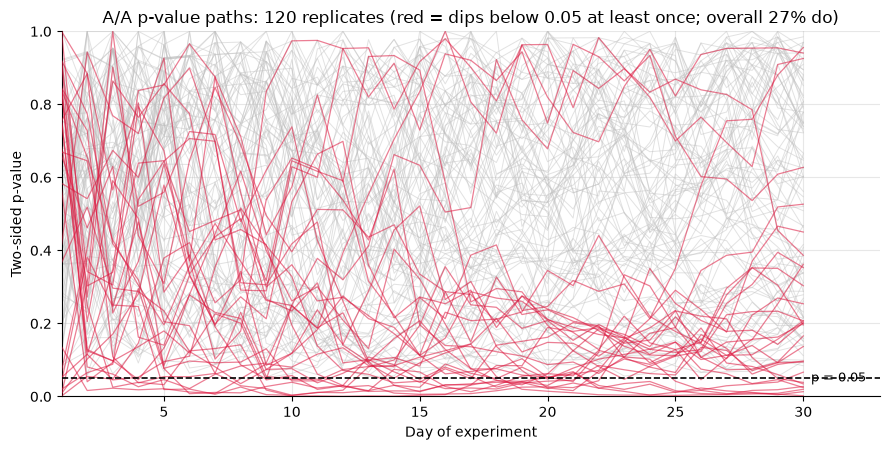

In [3]:
days = np.arange(1, HORIZON + 1)
fig, ax = plt.subplots(figsize=(9, 4.6))
n_show = 120
for i in range(n_show):
    if ever_sig[i]:
        ax.plot(days, pv0[i], color="crimson", lw=0.9, alpha=0.55, zorder=3)
    else:
        ax.plot(days, pv0[i], color="0.75", lw=0.7, alpha=0.45, zorder=2)
ax.axhline(ALPHA, color="black", ls="--", lw=1.2, zorder=4)
ax.text(30.3, ALPHA, "p = 0.05", va="center", fontsize=9)
ax.set_xlim(1, 33)
ax.set_ylim(0, 1)
ax.set_xlabel("Day of experiment")
ax.set_ylabel("Two-sided p-value")
ax.set_title(f"A/A p-value paths: {n_show} replicates "
             f"(red = dips below 0.05 at least once; overall {fpr_peek:.0%} do)")
plt.show()

How bad it gets depends on how often you look. Sweeping the number of equally spaced
looks over the same 30-day test shows the inflation curve — steep at first, then growing
roughly logarithmically (each extra look adds a highly correlated test, so the marginal
damage shrinks but never stops).

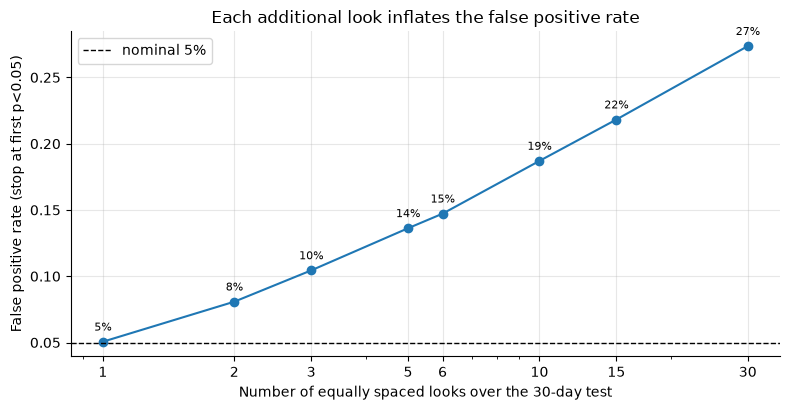

In [4]:
looks_grid = [1, 2, 3, 5, 6, 10, 15, 30]
fpr_by_looks = []
for k in looks_grid:
    idx = np.arange(1, k + 1) * (HORIZON // k) - 1          # equally spaced look days
    fpr_by_looks.append((pv0[:, idx] < ALPHA).any(axis=1).mean())

fig, ax = plt.subplots()
ax.plot(looks_grid, fpr_by_looks, "o-", color="tab:blue")
ax.axhline(ALPHA, color="black", ls="--", lw=1, label="nominal 5%")
for k, f in zip(looks_grid, fpr_by_looks):
    ax.annotate(f"{f:.0%}", (k, f), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xticks(looks_grid)
ax.set_xticklabels(looks_grid)
ax.set_xlabel("Number of equally spaced looks over the 30-day test")
ax.set_ylabel("False positive rate (stop at first p<0.05)")
ax.set_title("Each additional look inflates the false positive rate")
ax.legend()
plt.show()

## 2. Why: multiple looks are multiple tests on accumulating data

Each look computes a z-statistic on all data so far. Under H0, the sequence
$Z_1, Z_2, \dots$ is jointly Gaussian with

$$\mathrm{Corr}(Z_i, Z_j) = \sqrt{n_i / n_j} = \sqrt{t_i / t_j},$$

where $t = n/n_{\max}$ is the **information fraction**. Equivalently,
$Z(t) = B(t)/\sqrt{t}$ for a standard Brownian motion $B$ — the z-path is a rescaled
random walk. That one fact explains everything in this notebook:

- **It is a multiple-testing problem** — the family-wise error rate over looks is what
  inflates. (General multiplicity machinery:
  [../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb).)
- **But Bonferroni is the wrong fix.** Thirty daily looks at $\alpha/30$ would demand
  p < 0.0017 at every look including the final one — pricing the looks as if they were
  independent when adjacent looks correlate at $\sqrt{29/30} \approx 0.983$. Group-sequential
  boundaries (Section 3) model the joint distribution and charge far less.
- **Unlimited peeking is a guaranteed false positive.** By the law of the iterated
  logarithm, $|Z_n|$ exceeds *any* fixed boundary infinitely often under H0. "We'll just
  keep it running until it's significant" has a 100% success rate — that is the
  sequential version of the p-hacking in
  [../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb).

Empirical check of the correlation structure on our simulated A/A z-paths:

In [5]:
z0_daily = stats.norm.isf(pv0 / 2) * np.sign(conv_b0 / n_cum - conv_a0 / n_cum)
pairs = [(5, 10), (5, 30), (10, 30), (15, 30), (29, 30)]
corr_check = pd.DataFrame(
    [{"day_i": i, "day_j": j,
      "empirical_corr": np.corrcoef(z0_daily[:, i - 1], z0_daily[:, j - 1])[0, 1],
      "theory_sqrt(ni/nj)": np.sqrt(i / j)} for i, j in pairs]
)
print("Correlation of z-statistics across looks (A/A simulation):")
corr_check

Correlation of z-statistics across looks (A/A simulation):


,day_i,day_j,empirical_corr,theory_sqrt(ni/nj)
0,5,10,0.7070,0.7071
1,5,30,0.4212,0.4082
2,10,30,0.5784,0.5774
3,15,30,0.7117,0.7071
4,29,30,0.9836,0.9832


## 3. Group-sequential testing: O'Brien–Fleming alpha spending

The classical fix (from clinical trials — Pocock 1977, O'Brien & Fleming 1979, Lan &
DeMets 1983): **pre-specify the looks and spend the 5% error budget across them.**

An *alpha-spending function* $\alpha^*(t)$ gives the cumulative type-I error you allow by
information fraction $t$, with $\alpha^*(1) = \alpha$. The O'Brien–Fleming-style spending
function (spending $\alpha/2$ per side, the `gsDesign`/`ldbounds` convention)

$$\alpha^*(t) = 4 - 4\,\Phi\!\left(\frac{z_{1-\alpha/4}}{\sqrt{t}}\right)$$

spends almost nothing early and most of the budget at the end — the industry favorite,
because early stops are reserved for overwhelming effects and the final analysis stays
close to the fixed-horizon test.

Boundaries $b_k$ then solve, look by look,

$$P_{H_0}\!\big(|Z_1|<b_1,\dots,|Z_{k-1}|<b_{k-1},\, |Z_k|\ge b_k\big) = \alpha^*(t_k)-\alpha^*(t_{k-1}).$$

Because the $Z_k$ are a Markov (Brownian) sequence, these probabilities are computable by
**recursive numerical integration**: track the sub-density of surviving sample paths,
truncate it at each boundary, convolve with the next Gaussian increment. This is the
actual Lan–DeMets algorithm inside R's `gsDesign`/`ldbounds` — about 25 lines of numpy:

In [6]:
def obf_spending(t, alpha=ALPHA):
    """O'Brien-Fleming-style alpha-spending (two-sided, alpha/2 spent per side)."""
    t = np.asarray(t, dtype=float)
    return 4 * stats.norm.sf(stats.norm.ppf(1 - alpha / 4) / np.sqrt(t))


def gst_boundaries(t_frac, spend_cum, z_max=7.5, n_grid=6001):
    """Two-sided group-sequential z-boundaries for a cumulative spending schedule.

    Recursive numerical integration of the sub-density of S_k = B(t_k) (Brownian motion
    at the information fractions) — the Lan-DeMets algorithm.
    """
    t = np.asarray(t_frac, dtype=float)
    s = np.linspace(-z_max, z_max, n_grid)
    h = s[1] - s[0]
    f = stats.norm.pdf(s, scale=np.sqrt(t[0]))            # density of S_1
    bounds, spent = [], 0.0
    for k in range(len(t)):
        inc = spend_cum[k] - spent                        # error to spend at this look
        alive = f.sum() * h                               # mass of paths still running
        cum = np.cumsum(f) * h
        c_grid = s[s >= 0]
        inside = np.interp(c_grid, s, cum) - np.interp(-c_grid, s, cum)
        tail = alive - inside                             # P(|S_k| > c), decreasing in c
        c = np.interp(inc, tail[::-1], c_grid[::-1])      # crossing point on the S scale
        bounds.append(c / np.sqrt(t[k]))                  # back to the z scale
        spent = spend_cum[k]
        if k < len(t) - 1:                                # survivors continue to next look
            f = np.where(np.abs(s) <= c, f, 0.0)
            kern = stats.norm.pdf(s, scale=np.sqrt(t[k + 1] - t[k]))
            f = np.convolve(f, kern, mode="same") * h
    return np.array(bounds)


K = 5                                                     # weekly-ish looks: days 6,12,...,30
t_frac = np.arange(1, K + 1) / K
spend = obf_spending(t_frac)
obf_bounds = gst_boundaries(t_frac, spend)

boundary_table = pd.DataFrame({
    "look": np.arange(1, K + 1),
    "day": (t_frac * HORIZON).astype(int),
    "info_fraction": t_frac,
    "cumulative_alpha_spent": spend,
    "z_boundary": obf_bounds,
    "nominal_p_at_look": 2 * stats.norm.sf(obf_bounds),
})
print("O'Brien-Fleming-style boundaries (published Lan-DeMets values for K=5:")
print("  4.88, 3.36, 2.68, 2.29, 2.03 - ours should match to ~2 decimals)")
boundary_table

O'Brien-Fleming-style boundaries (published Lan-DeMets values for K=5:
  4.88, 3.36, 2.68, 2.29, 2.03 - ours should match to ~2 decimals)


,look,day,info_fraction,cumulative_alpha_spent,z_boundary,nominal_p_at_look
0,1,6,0.2,1.0777e-06,4.8769,1.0776e-06
1,2,12,0.4,7.8830e-04,3.3570,7.8787e-04
2,3,18,0.6,7.6161e-03,2.6804,7.3545e-03
3,4,24,0.8,2.4424e-02,2.2899,2.2030e-02
4,5,30,1.0,5.0000e-02,2.0313,4.2226e-02


Read the table like a practitioner:

- **Look 1 (day 6) needs |z| ≈ 4.9** — nominal p ≈ 1e-6. You only stop in week one for an
  effect so large it is unmissable. This is what protects you from the early-noise
  region where naive peeking does most of its damage.
- **The final look needs |z| ≈ 2.03 instead of 1.96** — nominal p ≈ 0.042 instead of
  0.05. That is the *entire* cost of buying five interim looks with an OBF schedule.
  Compare Bonferroni's p < 0.01 per look — the correlation structure is doing the work.

Two checks by simulation on realistic binomial data (not the Gaussian idealization):
the FPR under H0 should be back at 5%, while naive peeking at the same five looks
inflates to ~14%.

In [7]:
def simulate_look_counts(n_reps, chunk_users, n_looks, p_a, p_b, rng):
    """Cumulative counts at each of `n_looks` equally spaced looks."""
    ca = rng.binomial(chunk_users, p_a, size=(n_reps, n_looks)).cumsum(axis=1)
    cb = rng.binomial(chunk_users, p_b, size=(n_reps, n_looks)).cumsum(axis=1)
    n = chunk_users * np.arange(1, n_looks + 1)
    return ca, cb, n


def gst_outcome(z_looks, bounds):
    """First boundary crossing per replicate; returns (any_crossed, first_look_index)."""
    crossed = np.abs(z_looks) >= bounds
    any_c = crossed.any(axis=1)
    first = crossed.argmax(axis=1)                        # only meaningful where any_c
    return any_c, first


CHUNK = N_DAY * (HORIZON // K)                            # users/arm accrued between looks
ca_h0, cb_h0, n_looks5 = simulate_look_counts(100_000, CHUNK, K, P0, P0, rng)
z_h0 = z_stat(ca_h0, cb_h0, n_looks5)

fpr_obf, _ = gst_outcome(z_h0, obf_bounds)
fpr_naive5 = (np.abs(z_h0) >= Z975).any(axis=1)
cum_obf_h0 = np.maximum.accumulate(np.abs(z_h0) >= obf_bounds, axis=1).mean(axis=0)

print("Under H0 (100,000 A/A replicates, 5 looks):")
print(f"  naive p<0.05 at every look:  FPR = {fpr_naive5.mean():.3f}")
print(f"  OBF spending boundaries:     FPR = {fpr_obf.mean():.3f}   (target 0.050)")
print(f"  fixed-horizon (final only):  FPR = {(np.abs(z_h0[:, -1]) >= Z975).mean():.3f}")

Under H0 (100,000 A/A replicates, 5 looks):
  naive p<0.05 at every look:  FPR = 0.142
  OBF spending boundaries:     FPR = 0.050   (target 0.050)
  fixed-horizon (final only):  FPR = 0.050


FPR is controlled. Now the payoff side: under H1 (+0.5pp), a group-sequential test
should stop early on clear winners and give up almost no power relative to the
fixed-horizon test on the same data.

In [8]:
N_REPS_H1 = 20_000
ca_h1, cb_h1, _ = simulate_look_counts(N_REPS_H1, CHUNK, K, P0, P0 + TRUE_LIFT, rng)
z_h1 = z_stat(ca_h1, cb_h1, n_looks5)

stopped_h1, first_h1 = gst_outcome(z_h1, obf_bounds)
power_gst = stopped_h1.mean()
power_fixed = (np.abs(z_h1[:, -1]) >= Z975).mean()
power_final_gst = (np.abs(z_h1[:, -1]) >= obf_bounds[-1]).mean()

n_at_stop = 2 * CHUNK * np.where(stopped_h1, first_h1 + 1, K)     # users, both arms
n_fixed = 2 * CHUNK * K
stop_share = pd.Series(np.where(stopped_h1, first_h1 + 1, 0)).value_counts(normalize=True).sort_index()

print(f"Under H1 = +{TRUE_LIFT*100:.1f}pp ({N_REPS_H1:,} replicates):")
print(f"  power, fixed-horizon z-test at day 30:     {power_fixed:.1%}")
print(f"  power, OBF group-sequential (any look):    {power_gst:.1%}")
print(f"  power if forced to the final look only:    {power_final_gst:.1%}  (the 'stricter final look' cost)")
print(f"  mean sample size: {n_at_stop.mean():,.0f} vs fixed {n_fixed:,} "
      f"-> {1 - n_at_stop.mean()/n_fixed:.1%} average saving")
print("\nShare of replicates stopping at each look (0 = never crossed, ran to day 30):")
print((stop_share.rename_axis("stop_look").rename("share")).to_string())

Under H1 = +0.5pp (20,000 replicates):
  power, fixed-horizon z-test at day 30:     78.5%
  power, OBF group-sequential (any look):    77.2%
  power if forced to the final look only:    76.1%  (the 'stricter final look' cost)
  mean sample size: 49,060 vs fixed 60,000 -> 18.2% average saving

Share of replicates stopping at each look (0 = never crossed, ran to day 30):
stop_look
0    0.2283
1    0.0001
2    0.0490
3    0.2421
4    0.2802
5    0.2003


The trade in one sentence: **OBF gives up a percentage point or two of power at the
planned horizon and, in exchange, ends a large fraction of truly-winning tests one to
two weeks early** — with the false positive rate still exactly 5%. Under H0 there is
almost no early stopping (that is by design — `cum_obf_h0` above shows only ~2% of A/A
tests stop before the final look), so null tests keep their full sample and precision.

The boundary chart is the picture to draw on a whiteboard when asked about this:

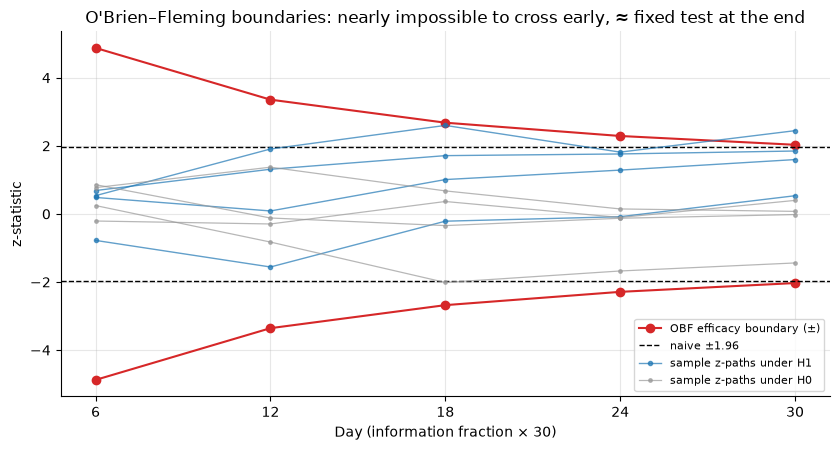

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
look_days = t_frac * HORIZON
ax.plot(look_days, obf_bounds, "o-", color="tab:red", label="OBF efficacy boundary (±)")
ax.plot(look_days, -obf_bounds, "o-", color="tab:red")
ax.axhline(Z975, color="black", ls="--", lw=1, label="naive ±1.96")
ax.axhline(-Z975, color="black", ls="--", lw=1)
for i, style in zip(range(4), ["-", "-", "-", "-"]):
    ax.plot(look_days, z_h1[i], style, color="tab:blue", lw=1.0, alpha=0.7,
            marker=".", ms=6, label="sample z-paths under H1" if i == 0 else None)
for i in range(4):
    ax.plot(look_days, z_h0[i], "-", color="0.6", lw=0.9, alpha=0.7, marker=".",
            ms=5, label="sample z-paths under H0" if i == 0 else None)
ax.set_xticks(look_days)
ax.set_xlabel("Day (information fraction × 30)")
ax.set_ylabel("z-statistic")
ax.set_title("O'Brien–Fleming boundaries: nearly impossible to cross early, ≈ fixed test at the end")
ax.legend(loc="lower right", fontsize=8)
plt.show()

## 4. Always-valid inference: the mixture SPRT

Group-sequential testing still assumes a *known horizon* and a *pre-specified look
schedule*. Modern experimentation platforms want neither: traffic is uncertain, tests
get extended, and thousands of non-statisticians refresh dashboards continuously. The
fix is a test that is valid at **every** sample size simultaneously — *always-valid*
(a.k.a. anytime-valid) inference, the design behind Optimizely's Stats Engine (Johari,
Koomen, Pekelis & Walsh, KDD 2017) and the modern e-value literature (Ramdas et al.).

The **mixture SPRT** for the lift $\theta = p_B - p_A$: with $\hat\theta_n$ approximately
$N(\theta, V_n)$, average the likelihood ratio over a Gaussian prior
$\theta \sim N(0, \tau^2)$ of plausible effects:

$$\Lambda_n \;=\; \sqrt{\frac{V_n}{V_n + \tau^2}}\;
  \exp\!\left(\frac{\hat\theta_n^2\,\tau^2}{2 V_n (V_n + \tau^2)}\right).$$

Under H0, $\Lambda_n$ is (approximately) a **nonnegative martingale with
$E[\Lambda_n] = 1$** — an *e-process*. Ville's inequality then gives the anytime
guarantee:

$$P_{H_0}\!\left(\sup_n \Lambda_n \ge 1/\alpha\right) \le \alpha ,$$

so the rule "stop and reject the first time $\Lambda_n \ge 20$" has FPR ≤ 5% **no matter
how often or how long you monitor**. The *always-valid p-value* is the running
$p_n = \min(1,\, 1/\max_{m\le n}\Lambda_m)$ — it only ever decreases, and thresholding it
at any time is safe. We monitor *daily for 60 days* — twice the earlier horizon, no
pre-registered look schedule at all.

In [10]:
def msprt_lambda(conv_a, conv_b, n, tau):
    """Mixture-SPRT likelihood ratio for a difference in proportions (normal approx)."""
    theta_hat = conv_b / n - conv_a / n
    pooled = (conv_a + conv_b) / (2 * n)
    v = 2 * pooled * (1 - pooled) / n                     # Var(theta_hat) under H0
    return np.sqrt(v / (v + tau**2)) * np.exp(theta_hat**2 * tau**2 / (2 * v * (v + tau**2)))


TAU = 0.005          # prior scale for plausible lifts: ~the MDE. Platforms fit this to history.
N_DAYS_LONG = 60

ca60, cb60, n60 = simulate_daily_counts(N_REPS, N_DAYS_LONG, P0, P0, rng)
lam_h0 = msprt_lambda(ca60, cb60, n60, TAU)
runmax_h0 = np.maximum.accumulate(lam_h0, axis=1)
cum_msprt_h0 = (runmax_h0 >= 1 / ALPHA).mean(axis=0)

pv60 = 2 * stats.norm.sf(np.abs(z_stat(ca60, cb60, n60)))
cum_naive_h0 = np.maximum.accumulate(pv60 < ALPHA, axis=1).mean(axis=0)

print(f"A/A monitoring, {N_REPS:,} replicates, one look per day for {N_DAYS_LONG} days:")
print(f"  naive p<0.05 peeking:  FPR by day 30 = {cum_naive_h0[29]:.1%},  by day 60 = {cum_naive_h0[-1]:.1%}")
print(f"  mSPRT (Lambda>=20):    FPR by day 30 = {cum_msprt_h0[29]:.1%},  by day 60 = {cum_msprt_h0[-1]:.1%}"
      f"   (guarantee: <=5% forever)")

A/A monitoring, 5,000 replicates, one look per day for 60 days:
  naive p<0.05 peeking:  FPR by day 30 = 27.9%,  by day 60 = 33.7%
  mSPRT (Lambda>=20):    FPR by day 30 = 1.0%,  by day 60 = 1.8%   (guarantee: <=5% forever)


The money plot for any "how do platforms let people peek?" conversation — cumulative
probability of having declared a (false) winner, as monitoring continues:

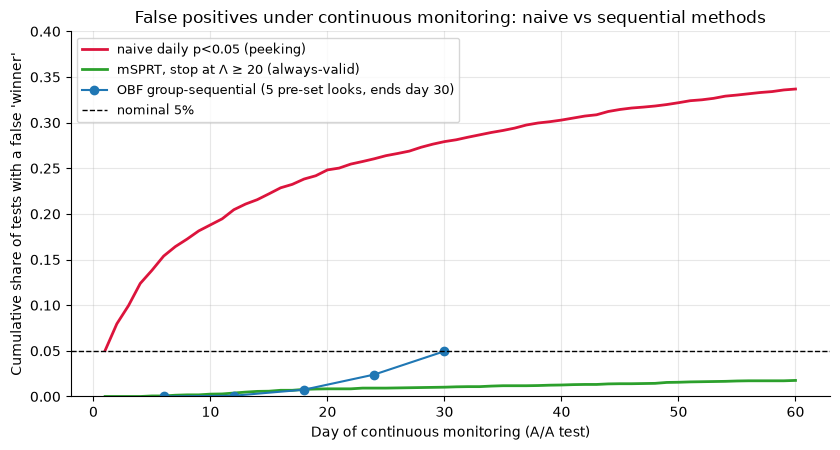

In [11]:
days60 = np.arange(1, N_DAYS_LONG + 1)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(days60, cum_naive_h0, color="crimson", lw=2, label="naive daily p<0.05 (peeking)")
ax.plot(days60, cum_msprt_h0, color="tab:green", lw=2, label="mSPRT, stop at Λ ≥ 20 (always-valid)")
ax.plot(look_days, cum_obf_h0, "o-", color="tab:blue", lw=1.5,
        label="OBF group-sequential (5 pre-set looks, ends day 30)")
ax.axhline(ALPHA, color="black", ls="--", lw=1, label="nominal 5%")
ax.set_ylim(0, 0.40)
ax.set_xlabel("Day of continuous monitoring (A/A test)")
ax.set_ylabel("Cumulative share of tests with a false 'winner'")
ax.set_title("False positives under continuous monitoring: naive vs sequential methods")
ax.legend(fontsize=9)
plt.show()

Anytime validity is not free. Under H1 the mSPRT needs more data than the fixed-horizon
test to reach the same power *at a fixed date* — the price of insuring every possible
stopping time. But it keeps accumulating evidence for as long as you let it run, with
no horizon to renegotiate:

Under H1 = +0.5pp, mSPRT with tau = 0.005 (daily looks):
  power by day 30: 47.5%   (fixed-horizon day-30 test: 80%)
  power by day 60: 85.3%
  median stop day among tests that stopped: 28


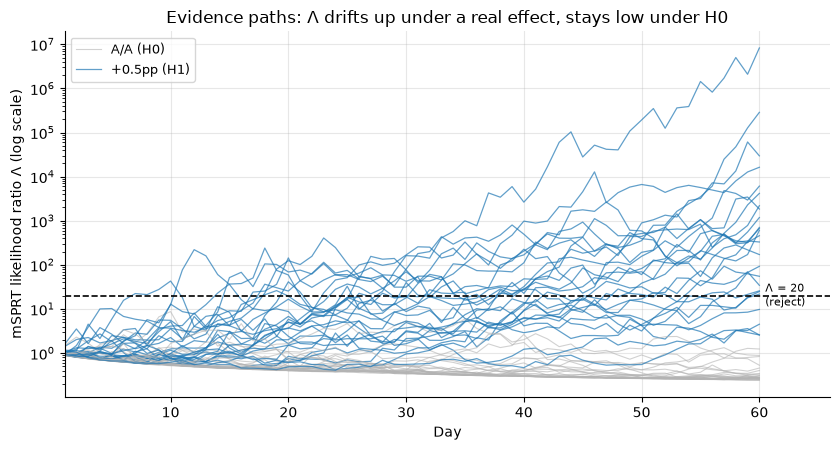

In [12]:
ca61, cb61, _ = simulate_daily_counts(N_REPS, N_DAYS_LONG, P0, P0 + TRUE_LIFT, rng)
lam_h1 = msprt_lambda(ca61, cb61, n60, TAU)
runmax_h1 = np.maximum.accumulate(lam_h1, axis=1)
crossed_h1 = runmax_h1 >= 1 / ALPHA
stop_day_h1 = np.where(crossed_h1[:, -1], crossed_h1.argmax(axis=1) + 1, np.nan)

print(f"Under H1 = +{TRUE_LIFT*100:.1f}pp, mSPRT with tau = {TAU} (daily looks):")
print(f"  power by day 30: {crossed_h1[:, 29].mean():.1%}   (fixed-horizon day-30 test: {power_planned:.0%})")
print(f"  power by day 60: {crossed_h1[:, -1].mean():.1%}")
print(f"  median stop day among tests that stopped: {np.nanmedian(stop_day_h1):.0f}")

# Sample evidence paths
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i in range(25):
    ax.plot(days60, lam_h0[i], color="0.7", lw=0.8, alpha=0.6,
            label="A/A (H0)" if i == 0 else None)
    ax.plot(days60, lam_h1[i], color="tab:blue", lw=0.9, alpha=0.7,
            label="+0.5pp (H1)" if i == 0 else None)
ax.axhline(1 / ALPHA, color="black", ls="--", lw=1.2)
ax.text(60.5, 1 / ALPHA, "Λ = 20\n(reject)", va="center", fontsize=8)
ax.set_yscale("log")
ax.set_xlim(1, 66)
ax.set_xlabel("Day")
ax.set_ylabel("mSPRT likelihood ratio Λ (log scale)")
ax.set_title("Evidence paths: Λ drifts up under a real effect, stays low under H0")
ax.legend(loc="upper left", fontsize=9)
plt.show()

The prior scale $\tau$ is the one tuning knob: it says which effect sizes the test is
"listening for." Small $\tau$ is efficient for small effects but slow to bank huge
ones; large $\tau$ is the reverse. Platforms fit $\tau$ to the historical distribution
of observed effects. It affects *efficiency only* — the anytime FPR guarantee holds for
every $\tau$:

In [13]:
rows = []
for tau in [0.001, 0.005, 0.02]:
    l0 = np.maximum.accumulate(msprt_lambda(ca60, cb60, n60, tau), axis=1)
    l1 = np.maximum.accumulate(msprt_lambda(ca61, cb61, n60, tau), axis=1)
    c1 = l1 >= 1 / ALPHA
    sd = np.where(c1[:, -1], c1.argmax(axis=1) + 1.0, np.nan)
    rows.append({"tau (pp)": tau * 100,
                 "FPR by day 60": (l0[:, -1] >= 1 / ALPHA).mean(),
                 "power by day 60": c1[:, -1].mean(),
                 "median stop day": np.nanmedian(sd)})
print("tau sensitivity (same simulated data, H1 = +0.5pp):")
pd.DataFrame(rows)

tau sensitivity (same simulated data, H1 = +0.5pp):


,tau (pp),FPR by day 60,power by day 60,median stop day
0,0.1,0.0000,0.444,50.0
1,0.5,0.0176,0.853,28.0
2,2.0,0.0160,0.766,29.0


## 5. Does Bayesian analysis solve peeking?

The claim you will hear: "Bayesian A/B testing doesn't have a peeking problem — the
posterior is valid whenever you compute it." The claim is *half* true, and the half
that is false is exactly the half that matters for stopping decisions.

**True part.** The posterior is a coherent summary of beliefs at any sample size. The
likelihood principle says the posterior does not depend on your intention to stop.
Nothing about peeking makes the posterior *wrong as a posterior*.

**False part.** A *stopping rule* that reacts to the posterior still stops on noise. If
you halt the first time $P(\text{B better} \mid \text{data}) > 0.95$, you are — under a
flat prior — halting the first time a one-sided p-value crosses 0.05, because
$P(\theta_B > \theta_A \mid \text{data}) \approx 1 - p_{\text{one-sided}}$. Same random walk, same
multiple looks, same inflation. Watch it happen on our A/A data (reused from Section 1,
so this is literally the same noise the p-value peeker saw):

In [14]:
def posterior_summary(conv_a, conv_b, n):
    """Normal approximation to the posterior of theta = pB - pA under Beta(1,1) priors."""
    ma, mb = (conv_a + 1) / (n + 2), (conv_b + 1) / (n + 2)
    var = ma * (1 - ma) / (n + 3) + mb * (1 - mb) / (n + 3)
    return mb - ma, np.sqrt(var)


def expected_loss(m, sd):
    """Expected loss of shipping A resp. B, for theta_B - theta_A ~ N(m, sd^2)."""
    zr = m / sd
    loss_ship_a = m * stats.norm.cdf(zr) + sd * stats.norm.pdf(zr)    # E[(theta_B-theta_A)^+]
    loss_ship_b = sd * stats.norm.pdf(zr) - m * stats.norm.cdf(-zr)   # E[(theta_A-theta_B)^+]
    return loss_ship_a, loss_ship_b


m0, sd0 = posterior_summary(conv_a0, conv_b0, n_cum)      # the Section-1 A/A tests
prob_b = stats.norm.cdf(m0 / sd0)                         # P(B better | data), approx

declare = (prob_b >= 0.95) | (prob_b <= 0.05)             # ship the "winner" either way
declared_ever = declare.any(axis=1).mean()
declared_final = declare[:, -1].mean()

print("Bayesian posterior-threshold stopping on A/A tests (daily checks, 30 days):")
print(f"  P(winner declared), evaluate once at day 30:      {declared_final:6.1%}")
print(f"  P(winner declared), stop at first crossing:       {declared_ever:6.1%}")
print("  ... the same inflation mechanism as p-value peeking (threshold 0.95 ~ one-sided p<0.05).")

Bayesian posterior-threshold stopping on A/A tests (daily checks, 30 days):
  P(winner declared), evaluate once at day 30:       10.0%
  P(winner declared), stop at first crossing:        46.5%
  ... the same inflation mechanism as p-value peeking (threshold 0.95 ~ one-sided p<0.05).


**The Bayesian rejoinder — expected-loss stopping.** A more sophisticated Bayesian
answer (VWO's SmartStats, Chris Stucchio's framework, covered properly in
[../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb))
is: stop when the **expected loss** of shipping the current leader drops below a
threshold of caring $\varepsilon$ — "if we're wrong, we expect to give up less than
0.01pp of conversion." This is a *decision-theoretic* guarantee, not an error-rate one.
Under an exact null it ships a "winner" in a large share of tests, and that is by
design: when both arms are identical, shipping either one costs exactly zero.

Expected-loss stopping (eps = 0.01pp) on the same A/A tests:
  ships a 'winner' within 30 days in 59.2% of tests
  ... but the true cost of every one of those ships is exactly 0 (the arms are identical).


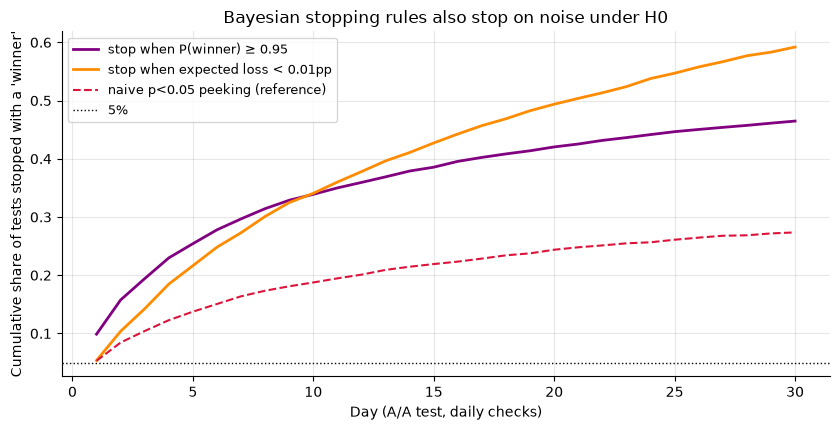

In [15]:
EPS = 1e-4                                                # threshold of caring: 0.01pp
la0, lb0 = expected_loss(m0, sd0)
ship0 = np.minimum(la0, lb0) < EPS
cum_loss_rule = np.maximum.accumulate(ship0, axis=1).mean(axis=0)
cum_thresh_rule = np.maximum.accumulate(declare, axis=1).mean(axis=0)

print(f"Expected-loss stopping (eps = {EPS*100:.2f}pp) on the same A/A tests:")
print(f"  ships a 'winner' within 30 days in {cum_loss_rule[-1]:.1%} of tests")
print("  ... but the true cost of every one of those ships is exactly 0 (the arms are identical).")

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.plot(days, cum_thresh_rule, color="purple", lw=2, label="stop when P(winner) ≥ 0.95")
ax.plot(days, cum_loss_rule, color="darkorange", lw=2, label=f"stop when expected loss < {EPS*100:.2f}pp")
ax.plot(days, np.maximum.accumulate(pv0 < ALPHA, axis=1).mean(axis=0),
        color="crimson", lw=1.5, ls="--", label="naive p<0.05 peeking (reference)")
ax.axhline(ALPHA, color="black", ls=":", lw=1, label="5%")
ax.set_xlabel("Day (A/A test, daily checks)")
ax.set_ylabel("Cumulative share of tests stopped with a 'winner'")
ax.set_title("Bayesian stopping rules also stop on noise under H0")
ax.legend(fontsize=9)
plt.show()

So is expected-loss stopping broken? No — it is answering a different question, and the
honest way to see both its logic and its limits is to give B a small *real* deficit.
With B truly worse by 0.2pp, the rule should mostly ship A; the failure mode to
quantify is how often early noise ships the worse arm B, and how much that costs:

In [16]:
ca_neg, cb_neg, _ = simulate_daily_counts(N_REPS, HORIZON, P0, P0 - 0.002, rng)
mn, sdn = posterior_summary(ca_neg, cb_neg, n_cum)
lan, lbn = expected_loss(mn, sdn)
ship_n = np.minimum(lan, lbn) < EPS

any_ship = ship_n.any(axis=1)
day_idx = np.clip(ship_n.argmax(axis=1), 0, HORIZON - 1)
r = np.arange(N_REPS)
ships_b = any_ship & (lbn[r, day_idx] < lan[r, day_idx])          # shipped the worse arm
ships_a = any_ship & ~ships_b

print(f"B truly worse by 0.20pp; expected-loss stopping with eps = {EPS*100:.2f}pp, 30 days:")
print(f"  ships A (correct):        {ships_a.mean():6.1%}")
print(f"  ships B (the worse arm):  {ships_b.mean():6.1%}")
print(f"  still running at day 30:  {1 - any_ship.mean():6.1%}")
print(f"  realized expected loss per experiment: 0.20pp x {ships_b.mean():.1%} = "
      f"{0.002 * ships_b.mean() * 100:.4f}pp   vs eps = {EPS*100:.2f}pp")

B truly worse by 0.20pp; expected-loss stopping with eps = 0.01pp, 30 days:
  ships A (correct):         64.6%
  ships B (the worse arm):   10.7%
  still running at day 30:   24.7%
  realized expected loss per experiment: 0.20pp x 10.7% = 0.0213pp   vs eps = 0.01pp


**The honest summary for the interview:**

- Bayesian *inference* has no peeking problem; Bayesian *stopping rules* that would fire
  on noise still fire on noise. If your stakeholders interpret "95% probability B is
  better" as "the effect is real" — a frequentist claim — then posterior-threshold
  stopping has exactly the inflation we simulated, and you need Section 3 or 4 instead.
- Expected-loss stopping is coherent *if the loss function is genuinely yours*: it
  controls the expected *magnitude* of mistakes (averaged over the prior), not their
  *frequency*. In the adverse simulation above, the realized loss can exceed
  $\varepsilon$ for unfavorable true effects — the guarantee is prior-averaged, not
  worst-case. When "we shipped a loser" carries organizational cost beyond the metric
  itself (credibility, roadmap churn), magnitude control is not enough.
- The prior does real work: a skeptical prior concentrated near zero shrinks early noisy
  estimates and slows stopping. Flat priors + threshold stopping is the worst of both
  worlds — and is what most "Bayesian" dashboards ship.

## 6. Practical guidance

| | Fixed horizon | Group-sequential (OBF) | Always-valid (mSPRT / e-values) | Bayesian expected loss |
|---|---|---|---|---|
| Peek and stop? | Never | At pre-set looks only | Any time | Any time |
| FPR under peeking | 25–30% (broken) | = α | ≤ α, at any horizon | Not controlled (by design) |
| Early stopping | None | Yes, for large effects | Yes, continuous | Yes, continuous |
| Cost | Discipline; opportunity cost | Slightly stricter final look (2.03 vs 1.96) | Less power at any fixed date | Guarantees magnitude, not frequency, of errors |
| Best when | Stable weekly cadence, mature org | Known horizon, few planned interims | Platform default, unknown horizon, many viewers | Loss function is real and agreed |

**When is fixed-horizon fine?** When the horizon is short and respected: pre-registered
duration (full weeks, to average over weekly seasonality — see
[01_ab_test_end_to_end.ipynb](./01_ab_test_end_to_end.ipynb)), results hidden or
clearly labeled "in flight," and a decision meeting only at the end. Many mature
experimentation cultures (much of big tech) run exactly this, because it is the most
powerful test per user. Monitoring for *harm* (guardrail collapses, bugs, SRM) is not
peeking-for-success and should be always-on — ideally with its own one-sided sequential
boundary so real incidents halt tests fast.

**What do commercial platforms do?** Sequential by default, because they cannot control
their users' eyeballs. Optimizely's Stats Engine is mSPRT-based always-valid p-values
and confidence sequences; Statsig, Eppo, and Amplitude offer sequential corrections
(mSPRT-style or group-sequential); VWO uses Bayesian expected-loss decisions. The trend
across the industry is "assume everyone peeks; make peeking safe," accepting the
efficiency cost relative to a disciplined fixed-horizon test.

**Pre-registration discipline** is what makes any of these guarantees real:

- Write down *before launch*: primary metric, α, horizon or look schedule, the stopping
  rule, and who decides. A rule chosen after seeing data is Section 1 again.
- Group-sequential means the look schedule is part of the design — you cannot add
  "just one more look" when the last one was almost significant (Pitfall 2 below).
- Separate the *monitoring* dashboard (engineers, guardrails, always-on) from the
  *decision* readout (gated by the pre-registered rule). Most peeking damage comes from
  giving launch authority to the monitoring view.
- If early stopping happens, report the estimate with its winner's-curse caveat
  (Pitfall 1) — the boundary that stopped you is also the floor on your estimate.

## 7. Pitfalls

### Pitfall 1 — the winner's curse of early stopping: stopped-early estimates are inflated

To stop at look $k$ you must have $|\hat\theta_k| \ge b_k \cdot SE_k$. Early looks have
large $SE$ and huge boundaries, so *conditional on stopping early, the estimate is
mechanically enormous* — even when the true effect is a modest +0.5pp. This is selection
bias on noise (same mechanism as regression to the mean in
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)),
and it survives a perfectly valid sequential design: the *test* is honest, the *naive
estimate at stop* is not.

In [17]:
est_h1 = (cb_h1 - ca_h1) / n_looks5                       # estimated lift at each look
se_looks = np.sqrt(2 * 0.0525 * (1 - 0.0525) / n_looks5)  # SE at each look (approx)

rows = []
for k in range(K):
    mask = stopped_h1 & (first_h1 == k)
    if mask.sum() > 0:
        rows.append({"stop_look": k + 1, "day": int(look_days[k]),
                     "n_reps": int(mask.sum()),
                     "mean_estimate_pp": est_h1[mask, k].mean() * 100,
                     "boundary_floor_pp": obf_bounds[k] * se_looks[k] * 100,
                     "inflation_vs_truth": est_h1[mask, k].mean() / TRUE_LIFT})
wc = pd.DataFrame(rows)
print(f"True lift: +{TRUE_LIFT*100:.1f}pp. Estimates conditional on the look at which OBF stopped:")
print(wc.to_string(index=False))
print(f"\nUnconditional mean estimate at day 30 (all reps): "
      f"{est_h1[:, -1].mean()*100:+.2f}pp  <- unbiased; conditioning on stopping is what biases")

True lift: +0.5pp. Estimates conditional on the look at which OBF stopped:
 stop_look  day  n_reps  mean_estimate_pp  boundary_floor_pp  inflation_vs_truth
         1    6       2            2.0250             1.9859              4.0500
         2   12     979            1.0927             0.9666              2.1853
         3   18    4842            0.7518             0.6301              1.5037
         4   24    5605            0.5678             0.4662              1.1356
         5   30    4006            0.4526             0.3699              0.9053

Unconditional mean estimate at day 30 (all reps): +0.50pp  <- unbiased; conditioning on stopping is what biases


A test that stops at week one reports ~4x the true effect — because ~4x is the minimum
it *could* report and still have stopped ("boundary_floor_pp" is the mechanical floor
$b_k \cdot SE_k$). Senior move: when presenting an early stop, quote the boundary floor
alongside the estimate, use a shrunken/bias-adjusted estimate where available, and never
extrapolate the early-stop lift into a revenue projection.

### Pitfall 2 — "not significant yet? extend the test"

Extending a test *because* the result is almost significant is peeking through the back
door: the extension decision is data-dependent, so the final test is conditioned on a
promising interim. Rule simulated below: run 30 days; if p ∈ [0.05, 0.15), run 15 more
days and test again at 0.05.

In [18]:
ca45, cb45, n45 = simulate_daily_counts(N_REPS, 45, P0, P0, rng)
pv45 = 2 * stats.norm.sf(np.abs(z_stat(ca45, cb45, n45)))
p30, p45 = pv45[:, 29], pv45[:, 44]

reject_extend = (p30 < ALPHA) | ((p30 >= ALPHA) & (p30 < 0.15) & (p45 < ALPHA))
print(f"FPR of the honest day-30 test:            {(p30 < ALPHA).mean():.3f}")
print(f"FPR with 'extend if 0.05 <= p < 0.15':    {reject_extend.mean():.3f}")
print("Extending on a data-dependent trigger inflates FPR. Extending for *data-independent*")
print("reasons (an outage corrupted week 1) is fine - the trigger is what matters.")

FPR of the honest day-30 test:            0.046
FPR with 'extend if 0.05 <= p < 0.15':    0.064
Extending on a data-dependent trigger inflates FPR. Extending for *data-independent*
reasons (an outage corrupted week 1) is fine - the trigger is what matters.


### Pitfall 3 — ad hoc "discipline" instead of a real correction

Teams that half-know about peeking invent folk rules: "we only call it if it's
significant two days in a row." Consecutive z-statistics correlate at ~0.98, so the
second day is almost a free rerun of the first — the rule dents the inflation but
lands nowhere near 5%:

In [19]:
two_in_a_row = ((pv0[:, :-1] < ALPHA) & (pv0[:, 1:] < ALPHA)).any(axis=1).mean()
print(f"FPR, stop at first single day p<0.05:          {fpr_peek:.1%}")
print(f"FPR, require p<0.05 two days in a row:         {two_in_a_row:.1%}")
print(f"FPR target:                                    {ALPHA:.1%}")
print("Folk corrections fail because adjacent looks are ~perfectly correlated;")
print("only boundaries derived from the joint distribution (Sec. 3) or martingales (Sec. 4) work.")

FPR, stop at first single day p<0.05:          27.4%
FPR, require p<0.05 two days in a row:         17.0%
FPR target:                                    5.0%
Folk corrections fail because adjacent looks are ~perfectly correlated;
only boundaries derived from the joint distribution (Sec. 3) or martingales (Sec. 4) work.


## 8. Interview corner

**1. "The PM checks the dashboard daily and wants to ship — day 9 of 30, p = 0.02.
What do you say?"**
Acknowledge the incentive (real opportunity cost), then quantify: daily peeking turns a
5% error rate into ~25–30% (cite an A/A simulation), and most early crossings are
transient. Distinguish monitoring (fine, always-on for guardrails) from deciding (needs
the pre-registered rule). For *this* test: p = 0.02 is z ≈ 2.3, nowhere near the ~3.9
an OBF boundary would demand at 30% information — so "keep running" is not just
process, it is the correct sequential decision. Constructive close: adopt a sequential
design (OBF looks or always-valid engine) so that next time "can we stop early?" has a
principled yes. Also warn that the day-9 estimate is winner's-curse inflated.

**2. "Explain alpha spending to a non-statistician."**
You have a 5% lifetime budget of false-positive risk for the experiment. Each look at
the data spends some of it. Alpha spending is the explicit budget plan: spend almost
nothing in the noisy early weeks (only stop for overwhelming effects), keep most of the
budget for the final read. The price of the interim looks is a final bar of ~2.03
instead of 1.96 — about p < 0.042. Cheap, because early looks at tiny boundaries spend
almost nothing.

**3. "Does Bayesian A/B testing fix peeking?"**
Layered answer: (a) the posterior itself is anytime-coherent — no problem there;
(b) *stopping* on a posterior threshold reproduces p-value peeking almost exactly
(with flat priors, $P(B>A) \approx 1 - p_{\text{one-sided}}$) — simulated FPR inflation looks
the same; (c) expected-loss stopping is a defensible different framework: it bounds the
expected *magnitude* of shipped mistakes, not their frequency, and the bound is
prior-averaged; (d) so the real question is what claim the org makes when it ships. If
"winner" means "real effect," you need frequentist sequential control; if it means
"safe bet under our loss function," Bayesian stopping is fine — with an honest prior.

**4. "You stopped at look 2 of 5 with +1.9pp on a +0.5pp-powered test. What goes in the
exec summary?"**
Winner's curse: conditional on stopping at look 2, the estimate must exceed
$b_2 \cdot SE_2$, so it is biased upward severely (our simulation: ~2–4x). Report the
decision (ship) and a deflated estimate: the boundary floor, a bias-adjusted/median-unbiased
estimate, or "likely between the MDE and the point estimate." Never feed the raw
early-stop number into revenue forecasts.

**5. "Group-sequential vs always-valid — when would you choose each?"**
GST: known horizon, few pre-plannable looks, you want maximum power at the planned end —
classic for a big launch review cadence. Always-valid (mSPRT/e-values): unknown or
elastic horizon, continuous monitoring by many stakeholders, platform-wide default —
you pay efficiency at any fixed date for validity at every date. Both are "alpha under
control"; they differ in where the power loss sits.

**6. "Why not just Bonferroni over the looks?"**
Looks are nearly perfectly correlated tests on nested data, and Bonferroni prices them
as independent: 30 daily looks would demand p < 0.0017 *including the final one*,
wrecking power. Sequential boundaries integrate over the joint (Markov) distribution of
the z-path, so the same 5% budget buys a final look at ~0.042. Bonferroni is a
worst-case bound; here the dependence structure is fully known, so use it.

**7. "What happens if you just keep an unadjusted test running until it's significant?"**
It will be, with probability 1 — law of the iterated logarithm: $|Z_n|$ recrosses any
fixed boundary infinitely often under H0. The FPR-vs-looks curve never plateaus. This is
why "run until significant" is not a strategy but a guarantee of shipping noise, and why
always-valid methods must use boundaries that grow like $\sqrt{\log n}$ rather than stay
flat.

## 9. Key takeaways

- A fixed-horizon test checked daily is not a 5% test; over 30 daily looks the false
  positive rate is ~25–30%, most crossings happen early, and most are transient.
- The mechanism is multiple *correlated* tests on accumulating data: $Z(t)=B(t)/\sqrt{t}$.
  Bonferroni ignores the correlation (too conservative); folk rules like "two days in a
  row" ignore it the other way (still ~3x the nominal error rate).
- Group-sequential testing pre-specifies looks and spends alpha across them. O'Brien–
  Fleming spending makes early stops nearly free: FPR stays at 5%, big effects stop
  weeks early, and the final look tightens only from 1.96 to ~2.03 (p ≈ 0.042).
- Boundaries come from the joint distribution of the z-path — computable by recursive
  numerical integration (Lan–DeMets) or calibratable by simulation; both are done above.
- Always-valid inference (mSPRT / e-processes) uses Ville's inequality on a likelihood-
  ratio martingale: valid under *any* peeking pattern, forever; the cost is lower power
  at any fixed date, tunable via the mixture scale $\tau$.
- Bayesian posteriors are peek-proof; Bayesian *stopping rules* are not. Posterior-
  threshold stopping ≈ p-value peeking. Expected-loss stopping controls the magnitude of
  mistakes (prior-averaged), not their frequency — fine iff that is really your loss.
- Early-stopped estimates are winner's-curse inflated by construction (the boundary is a
  floor on the reported effect). Deflate before anyone builds a revenue model on them.
- Fixed-horizon remains the most powerful design per user *if* the org can actually not
  act mid-test; commercial platforms went sequential-by-default because orgs can't.
- Pre-register the stopping rule, whatever it is. Every guarantee in this notebook is a
  guarantee about a rule chosen before the data arrived.

## 10. Exercises

**Exercise 1 — Pocock boundaries.** The other classic group-sequential design uses a
*constant* z-boundary at every look. Calibrate the K=5 Pocock boundary by simulation
(hint: it is the 95th percentile of $\max_k |Z_k|$ over null z-paths), then compare it
to OBF on the Section-3 H1 simulation: power, stopping profile, expected sample size,
and the nominal p-value required at the final look. Why does industry mostly prefer
OBF-style designs?

In [20]:
# --- Solution ---
M = 200_000
increments = rng.normal(size=(M, K)) * np.sqrt(1 / K)
z_paths = increments.cumsum(axis=1) / np.sqrt(t_frac)     # null z-process at the looks
c_pocock = np.quantile(np.abs(z_paths).max(axis=1), 1 - ALPHA)
pocock_bounds = np.full(K, c_pocock)

stopped_pk, first_pk = gst_outcome(z_h1, pocock_bounds)   # same H1 data as Section 3
n_stop_pk = 2 * CHUNK * np.where(stopped_pk, first_pk + 1, K)

cmp = pd.DataFrame({
    "boundary_look1": [obf_bounds[0], c_pocock],
    "boundary_final": [obf_bounds[-1], c_pocock],
    "nominal_p_final": 2 * stats.norm.sf([obf_bounds[-1], c_pocock]),
    "power_H1": [power_gst, stopped_pk.mean()],
    "median_stop_look(stoppers)": [np.median(first_h1[stopped_h1] + 1),
                                   np.median(first_pk[stopped_pk] + 1)],
    "mean_total_N": [n_at_stop.mean(), n_stop_pk.mean()],
}, index=["OBrien-Fleming", "Pocock"])
print(f"Calibrated Pocock constant boundary for K=5: {c_pocock:.3f} (literature: ~2.41)")
cmp

Calibrated Pocock constant boundary for K=5: 2.411 (literature: ~2.41)


,boundary_look1,boundary_final,nominal_p_final,power_H1,median_stop_look(stoppers),mean_total_N
OBrien-Fleming,4.8769,2.0313,0.0422,0.7717,4.0,49059.6
Pocock,2.4109,2.4109,0.0159,0.6855,3.0,43123.8


Pocock stops earlier on true effects (flat boundary is reachable at look 1–2) but pays
for it twice: noticeably lower power at the same horizon, and a harsh final look
(p ≈ 0.016 instead of ≈ 0.042) — so a "conventionally significant" p = 0.03 at the end
is *not significant* under Pocock. That conversation with stakeholders is why OBF-style
spending, which keeps the final look near 1.96, dominates in industry.

**Exercise 2 — verify the martingale property behind the mSPRT.** Anytime validity
rests on $E_{H_0}[\Lambda_n] = 1$ for all $n$ plus Ville's inequality. Using the
Section-4 A/A runs, (a) plot the cross-replicate mean of $\Lambda_n$ over the 60 days
with a ±2 SE band; (b) compare the empirical crossing rate of $\Lambda \ge 20$ with the
Ville bound 1/20. What would a mean drifting well above 1 indicate?

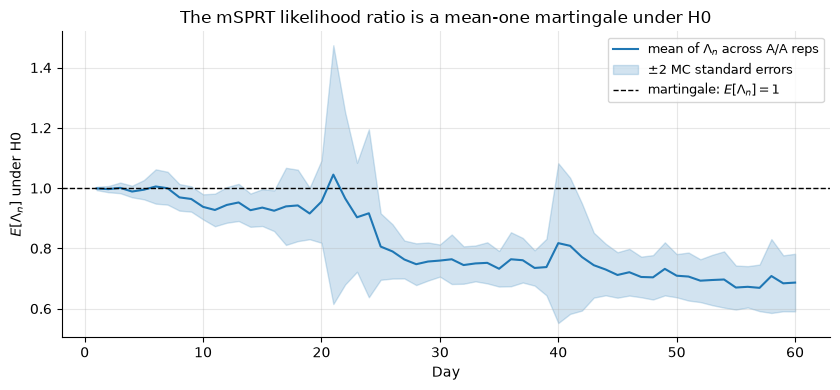

Empirical P(sup Lambda >= 20) over 60 days: 0.018  <=  Ville bound 0.050
A mean drifting above 1 would mean the H0 model is misspecified (e.g., wrong variance,
dependence, drift) - the 'martingale' would leak type-I error beyond alpha.


In [21]:
# --- Solution ---
lam_mean = lam_h0.mean(axis=0)
lam_se = lam_h0.std(axis=0) / np.sqrt(N_REPS)

fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.plot(days60, lam_mean, color="tab:blue", lw=1.5, label=r"mean of $\Lambda_n$ across A/A reps")
ax.fill_between(days60, lam_mean - 2 * lam_se, lam_mean + 2 * lam_se,
                color="tab:blue", alpha=0.2, label="±2 MC standard errors")
ax.axhline(1.0, color="black", ls="--", lw=1, label=r"martingale: $E[\Lambda_n]=1$")
ax.set_xlabel("Day")
ax.set_ylabel(r"$E[\Lambda_n]$ under H0")
ax.set_title("The mSPRT likelihood ratio is a mean-one martingale under H0")
ax.legend(fontsize=9)
plt.show()

ville = (runmax_h0[:, -1] >= 1 / ALPHA).mean()
print(f"Empirical P(sup Lambda >= 20) over 60 days: {ville:.3f}  <=  Ville bound {ALPHA:.3f}")
print("A mean drifting above 1 would mean the H0 model is misspecified (e.g., wrong variance,")
print("dependence, drift) - the 'martingale' would leak type-I error beyond alpha.")

The empirical crossing rate sits well *below* 5%: Ville's inequality is conservative
for any finite horizon (the supremum bound is over infinite time, and the mixture is
not perfectly matched to any single alternative). That conservatism is the efficiency
price identified in Section 4.

**Exercise 3 — rescue a peeked test (retroactive alpha spending).** Your team peeked at
days 10 and 20 of a 30-day test, agreeing they would only have stopped for something
"dramatic" — |z| ≥ 2.576 (p < 0.01). Neither peek fired. What final-look critical value
keeps the *overall* FPR at 5%? Calibrate by simulation. Then show why the rescue would
have been impossible had they peeked at the usual 1.96.

In [22]:
# --- Solution ---
M = 400_000
t3 = np.array([1 / 3, 2 / 3, 1.0])
inc3 = rng.normal(size=(M, 3)) * np.sqrt(np.diff(np.concatenate([[0.0], t3])))
z3 = inc3.cumsum(axis=1) / np.sqrt(t3)

peeked = (np.abs(z3[:, 0]) >= 2.576) | (np.abs(z3[:, 1]) >= 2.576)
spent_2576 = peeked.mean()
remaining = ALPHA - spent_2576
alive = ~peeked
c_final = np.quantile(np.abs(z3[alive, 2]), 1 - remaining / alive.mean())

peeked_196 = (np.abs(z3[:, 0]) >= Z975) | (np.abs(z3[:, 1]) >= Z975)
print(f"Alpha already spent by two |z|>=2.576 peeks: {spent_2576:.4f}")
print(f"Remaining budget for the final look:         {remaining:.4f}")
print(f"Corrected final critical value:              {c_final:.3f}  "
      f"(nominal p = {2*stats.norm.sf(c_final):.4f}, vs 1.96/0.05 unpeeked)")
print(f"\nHad the peeks used 1.96: alpha spent = {peeked_196.mean():.4f} > {ALPHA} -> "
      "no final threshold can restore 5%.")
print("Moral: informal peeks can sometimes be paid for after the fact - but only if they were")
print("conservative, and only if you can state honestly what rule you would have stopped under.")

Alpha already spent by two |z|>=2.576 peeks: 0.0177
Remaining budget for the final look:         0.0323
Corrected final critical value:              2.048  (nominal p = 0.0405, vs 1.96/0.05 unpeeked)

Had the peeks used 1.96: alpha spent = 0.0837 > 0.05 -> no final threshold can restore 5%.
Moral: informal peeks can sometimes be paid for after the fact - but only if they were
conservative, and only if you can state honestly what rule you would have stopped under.
